In [1]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import glob
import zipfile

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
from google.colab import files

uploaded = files.upload()

print("Dataset uploaded successfully!")

Saving beijing+multi+site+air+quality+data.zip to beijing+multi+site+air+quality+data.zip
Dataset uploaded successfully!


In [4]:
import zipfile
import os

zip_path = "beijing+multi+site+air+quality+data.zip"
extract_path = "/content/beijing_air_quality"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")

# Display extracted files
for root, dirs, files_list in os.walk(extract_path):
    for file in files_list:
        print(file)

Dataset extracted successfully!
test.csv
PRSA2017_Data_20130301-20170228.zip
2A2478DC-8517-4490-9FA7-36F9A7A542BE.JPG
data.csv


In [5]:
import os
import zipfile
import pandas as pd

# Check the CSV files
for filename in ["data.csv", "test.csv"]:
    filepath = os.path.join(extract_path, filename)

    df = pd.read_csv(filepath)

    print(f"\n{filename}")
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())
    display(df.head())

# Inspect the nested ZIP
nested_zip = os.path.join(
    extract_path,
    "PRSA2017_Data_20130301-20170228.zip"
)

with zipfile.ZipFile(nested_zip, 'r') as zip_ref:
    print("\nFiles inside the nested ZIP:")
    for file in zip_ref.namelist():
        print(file)


data.csv
Shape: (503, 7)
Columns: ['Date', 'Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume']


,Date,Open,High,Low,Close,Adj Close,Volume
0,2018-07-02,183.820007,187.300003,183.419998,187.179993,182.199005,17731300
1,2018-07-03,187.789993,187.949997,183.539993,183.919998,179.025772,13954800
2,2018-07-05,185.259995,186.410004,184.279999,185.399994,180.466370,16604200
3,2018-07-06,185.419998,188.429993,185.199997,187.970001,182.967972,17485200
4,2018-07-09,189.500000,190.679993,189.300003,190.580002,185.508545,19756600



test.csv
Shape: (503, 7)
Columns: ['Date', 'Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume']


,Date,Open,High,Low,Close,Adj Close,Volume
0,2018-07-02,43.060001,45.000000,42.750000,44.980000,44.980000,16703600
1,2018-07-03,45.360001,45.480000,43.799999,43.889999,43.889999,14237500
2,2018-07-05,44.070000,45.110001,43.549999,45.060001,45.060001,16172000
3,2018-07-06,44.910000,46.750000,44.610001,46.650002,46.650002,23740700
4,2018-07-09,46.740002,46.900002,42.080002,44.139999,44.139999,107582400



Files inside the nested ZIP:
PRSA_Data_20130301-20170228/
PRSA_Data_20130301-20170228/PRSA_Data_Aotizhongxin_20130301-20170228.csv
PRSA_Data_20130301-20170228/PRSA_Data_Changping_20130301-20170228.csv
PRSA_Data_20130301-20170228/PRSA_Data_Dingling_20130301-20170228.csv
PRSA_Data_20130301-20170228/PRSA_Data_Dongsi_20130301-20170228.csv
PRSA_Data_20130301-20170228/PRSA_Data_Guanyuan_20130301-20170228.csv
PRSA_Data_20130301-20170228/PRSA_Data_Gucheng_20130301-20170228.csv
PRSA_Data_20130301-20170228/PRSA_Data_Huairou_20130301-20170228.csv
PRSA_Data_20130301-20170228/PRSA_Data_Nongzhanguan_20130301-20170228.csv
PRSA_Data_20130301-20170228/PRSA_Data_Shunyi_20130301-20170228.csv
PRSA_Data_20130301-20170228/PRSA_Data_Tiantan_20130301-20170228.csv
PRSA_Data_20130301-20170228/PRSA_Data_Wanliu_20130301-20170228.csv
PRSA_Data_20130301-20170228/PRSA_Data_Wanshouxigong_20130301-20170228.csv


In [6]:
import zipfile
import os

nested_zip = os.path.join(
    extract_path,
    "PRSA2017_Data_20130301-20170228.zip"
)

station_folder = "/content/Beijing_Air_Quality_Data"

with zipfile.ZipFile(nested_zip, 'r') as zip_ref:
    zip_ref.extractall(station_folder)

print("All station datasets extracted successfully!")

# Count CSV files
csv_files = []

for root, dirs, files_list in os.walk(station_folder):
    for file in files_list:
        if file.endswith(".csv"):
            csv_files.append(os.path.join(root, file))

print("\nNumber of station datasets:", len(csv_files))

print("\nStation datasets:")
for file in csv_files:
    print(os.path.basename(file))

All station datasets extracted successfully!

Number of station datasets: 12

Station datasets:
PRSA_Data_Wanliu_20130301-20170228.csv
PRSA_Data_Changping_20130301-20170228.csv
PRSA_Data_Guanyuan_20130301-20170228.csv
PRSA_Data_Huairou_20130301-20170228.csv
PRSA_Data_Shunyi_20130301-20170228.csv
PRSA_Data_Tiantan_20130301-20170228.csv
PRSA_Data_Nongzhanguan_20130301-20170228.csv
PRSA_Data_Dongsi_20130301-20170228.csv
PRSA_Data_Wanshouxigong_20130301-20170228.csv
PRSA_Data_Gucheng_20130301-20170228.csv
PRSA_Data_Dingling_20130301-20170228.csv
PRSA_Data_Aotizhongxin_20130301-20170228.csv


In [7]:
import pandas as pd
import os

# Read and combine all 12 station datasets
dataframes = []

for file in csv_files:
    df = pd.read_csv(file)
    dataframes.append(df)

# Combine into one DataFrame
air_quality_df = pd.concat(dataframes, ignore_index=True)

print("All datasets combined successfully!")

print("\nCombined dataset shape:")
print(air_quality_df.shape)

print("\nColumn names:")
print(air_quality_df.columns.tolist())

print("\nFirst five rows:")
display(air_quality_df.head())

All datasets combined successfully!

Combined dataset shape:
(420768, 18)

Column names:
['No', 'year', 'month', 'day', 'hour', 'PM2.5', 'PM10', 'SO2', 'NO2', 'CO', 'O3', 'TEMP', 'PRES', 'DEWP', 'RAIN', 'wd', 'WSPM', 'station']

First five rows:


,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
0,1,2013,3,1,0,8.0,8.0,6.0,28.0,400.0,52.0,-0.7,1023.0,-18.8,0.0,NNW,4.4,Wanliu
1,2,2013,3,1,1,9.0,9.0,6.0,28.0,400.0,50.0,-1.1,1023.2,-18.2,0.0,N,4.7,Wanliu
2,3,2013,3,1,2,3.0,6.0,NaN,19.0,400.0,55.0,-1.1,1023.5,-18.2,0.0,NNW,5.6,Wanliu
3,4,2013,3,1,3,11.0,30.0,8.0,14.0,NaN,NaN,-1.4,1024.5,-19.4,0.0,NW,3.1,Wanliu
4,5,2013,3,1,4,3.0,13.0,9.0,NaN,300.0,54.0,-2.0,1025.2,-19.5,0.0,N,2.0,Wanliu


In [8]:
# Dataset information
print("DATASET INFORMATION")
print("=" * 50)

air_quality_df.info()

# Statistical summary
print("\nDESCRIPTIVE STATISTICS")
display(air_quality_df.describe())

# Number of records per station
print("\nRECORDS PER MONITORING STATION")
display(air_quality_df['station'].value_counts())

# Dataset dimensions
print("\nDATASET DIMENSIONS")
print("Rows:", air_quality_df.shape[0])
print("Columns:", air_quality_df.shape[1])

DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 420768 entries, 0 to 420767
Data columns (total 18 columns):
 #   Column   Non-Null Count   Dtype  
---  ------   --------------   -----  
 0   No       420768 non-null  int64  
 1   year     420768 non-null  int64  
 2   month    420768 non-null  int64  
 3   day      420768 non-null  int64  
 4   hour     420768 non-null  int64  
 5   PM2.5    412029 non-null  float64
 6   PM10     414319 non-null  float64
 7   SO2      411747 non-null  float64
 8   NO2      408652 non-null  float64
 9   CO       400067 non-null  float64
 10  O3       407491 non-null  float64
 11  TEMP     420370 non-null  float64
 12  PRES     420375 non-null  float64
 13  DEWP     420365 non-null  float64
 14  RAIN     420378 non-null  float64
 15  wd       418946 non-null  object 
 16  WSPM     420450 non-null  float64
 17  station  420768 non-null  object 
dtypes: float64(11), int64(5), object(2)
memory usage: 57.8+ MB

DESCRIPTIVE STATISTICS


,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,WSPM
count,420768.000000,420768.000000,420768.000000,420768.000000,420768.000000,412029.000000,414319.000000,411747.000000,408652.000000,400067.000000,407491.000000,420370.000000,420375.000000,420365.000000,420378.000000,420450.000000
mean,17532.500000,2014.662560,6.522930,15.729637,11.500000,79.793428,104.602618,15.830835,50.638586,1230.766454,57.372271,13.538976,1010.746982,2.490822,0.064476,1.729711
std,10122.116943,1.177198,3.448707,8.800102,6.922195,80.822391,91.772426,21.650603,35.127912,1160.182716,56.661607,11.436139,10.474055,13.793847,0.821004,1.246386
min,1.000000,2013.000000,1.000000,1.000000,0.000000,2.000000,2.000000,0.285600,1.026500,100.000000,0.214200,-19.900000,982.400000,-43.400000,0.000000,0.000000
25%,8766.750000,2014.000000,4.000000,8.000000,5.750000,20.000000,36.000000,3.000000,23.000000,500.000000,11.000000,3.100000,1002.300000,-8.900000,0.000000,0.900000
50%,17532.500000,2015.000000,7.000000,16.000000,11.500000,55.000000,82.000000,7.000000,43.000000,900.000000,45.000000,14.500000,1010.400000,3.100000,0.000000,1.400000
75%,26298.250000,2016.000000,10.000000,23.000000,17.250000,111.000000,145.000000,20.000000,71.000000,1500.000000,82.000000,23.300000,1019.000000,15.100000,0.000000,2.200000
max,35064.000000,2017.000000,12.000000,31.000000,23.000000,999.000000,999.000000,500.000000,290.000000,10000.000000,1071.000000,41.600000,1042.800000,29.100000,72.500000,13.200000



RECORDS PER MONITORING STATION


,count
station,
Wanliu,35064
Changping,35064
Guanyuan,35064
Huairou,35064
Shunyi,35064
Tiantan,35064
Nongzhanguan,35064
Dongsi,35064
Wanshouxigong,35064



DATASET DIMENSIONS
Rows: 420768
Columns: 18


MISSING VALUE ANALYSIS


,Missing Values,Percentage (%)
CO,20701,4.919813
O3,13277,3.155421
NO2,12116,2.879497
SO2,9021,2.143937
PM2.5,8739,2.076916
PM10,6449,1.532674
wd,1822,0.433018
DEWP,403,0.095777
TEMP,398,0.094589
PRES,393,0.093401



Total missing values: 74027


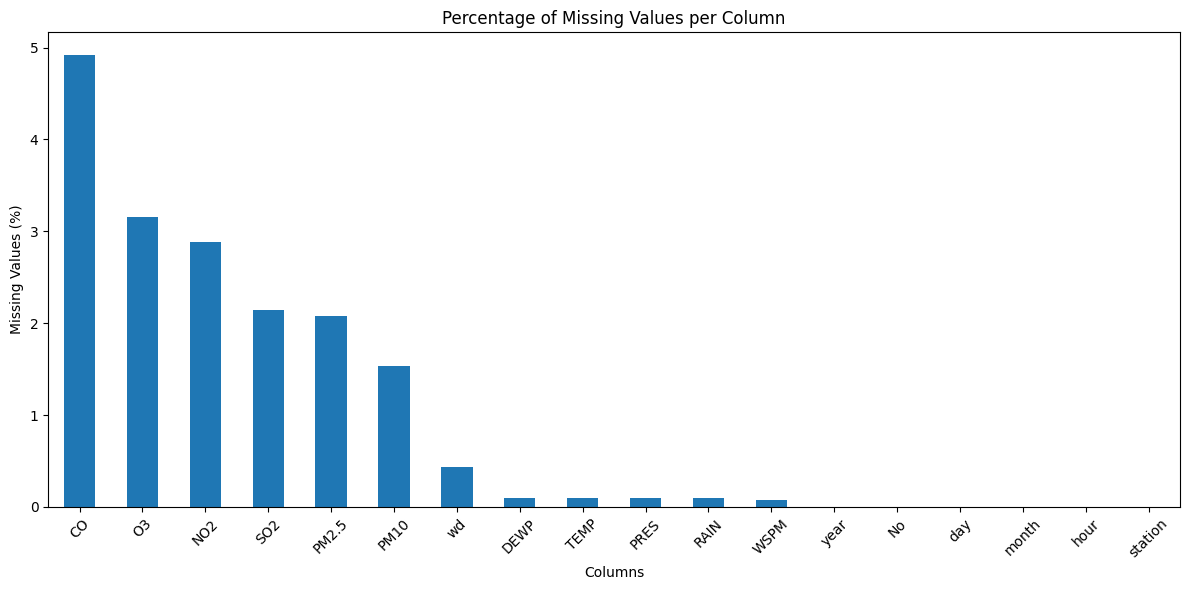

In [9]:
# Calculate missing values
missing_values = air_quality_df.isnull().sum()

# Calculate missing percentages
missing_percentage = (
    air_quality_df.isnull().sum() / len(air_quality_df)
) * 100

# Create a summary table
missing_summary = pd.DataFrame({
    'Missing Values': missing_values,
    'Percentage (%)': missing_percentage
})

# Sort from highest to lowest missing values
missing_summary = missing_summary.sort_values(
    by='Missing Values',
    ascending=False
)

print("MISSING VALUE ANALYSIS")
display(missing_summary)

# Total missing values
print("\nTotal missing values:", air_quality_df.isnull().sum().sum())

# Visualize missing values
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
missing_summary['Percentage (%)'].plot(kind='bar')
plt.title('Percentage of Missing Values per Column')
plt.xlabel('Columns')
plt.ylabel('Missing Values (%)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [10]:
# Check duplicate records
duplicate_count = air_quality_df.duplicated().sum()

print("DUPLICATE VALUE ANALYSIS")
print("=" * 40)

print("Total records:", len(air_quality_df))
print("Duplicate records:", duplicate_count)

# Check duplicated station-time observations
duplicate_time = air_quality_df.duplicated(
    subset=['year', 'month', 'day', 'hour', 'station']
).sum()

print("\nDuplicate station-time records:", duplicate_time)

DUPLICATE VALUE ANALYSIS
Total records: 420768
Duplicate records: 0

Duplicate station-time records: 0


In [11]:
# Create a copy of the original dataset
cleaned_df = air_quality_df.copy()

# Create a datetime column
cleaned_df['datetime'] = pd.to_datetime(
    cleaned_df[['year', 'month', 'day', 'hour']]
)

# Sort by station and datetime
cleaned_df = cleaned_df.sort_values(
    by=['station', 'datetime']
).reset_index(drop=True)

# Numerical columns to interpolate
numerical_columns = [
    'PM2.5', 'PM10', 'SO2', 'NO2', 'CO', 'O3',
    'TEMP', 'PRES', 'DEWP', 'RAIN', 'WSPM'
]

# Interpolate within each station
for column in numerical_columns:
    cleaned_df[column] = cleaned_df.groupby('station')[column].transform(
        lambda x: x.interpolate(method='linear', limit_direction='both')
    )

# Fill missing wind direction within each station
cleaned_df['wd'] = cleaned_df.groupby('station')['wd'].transform(
    lambda x: x.ffill().bfill()
)

print("Missing value treatment completed!")

print("\nMissing values after treatment:")
print(cleaned_df.isnull().sum())

print("\nTotal remaining missing values:",
      cleaned_df.isnull().sum().sum())

Missing value treatment completed!

Missing values after treatment:
No          0
year        0
month       0
day         0
hour        0
PM2.5       0
PM10        0
SO2         0
NO2         0
CO          0
O3          0
TEMP        0
PRES        0
DEWP        0
RAIN        0
wd          0
WSPM        0
station     0
datetime    0
dtype: int64

Total remaining missing values: 0


In [12]:
# Identify outliers using the IQR method

outlier_columns = [
    'PM2.5', 'PM10', 'SO2', 'NO2', 'CO', 'O3',
    'TEMP', 'PRES', 'DEWP', 'RAIN', 'WSPM'
]

outlier_results = []

for column in outlier_columns:
    Q1 = cleaned_df[column].quantile(0.25)
    Q3 = cleaned_df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = cleaned_df[
        (cleaned_df[column] < lower_bound) |
        (cleaned_df[column] > upper_bound)
    ]

    outlier_results.append({
        'Column': column,
        'Lower Bound': lower_bound,
        'Upper Bound': upper_bound,
        'Outlier Count': len(outliers)
    })

outlier_summary = pd.DataFrame(outlier_results)

print("OUTLIER DETECTION USING IQR")
display(outlier_summary)

OUTLIER DETECTION USING IQR


,Column,Lower Bound,Upper Bound,Outlier Count
0,PM2.5,-116.50,247.50,19612
1,PM10,-127.50,308.50,15150
2,SO2,-22.50,45.50,36626
3,NO2,-49.00,143.00,7255
4,CO,-1000.00,3000.00,29224
5,O3,-98.00,190.00,16662
6,TEMP,-27.20,53.60,0
7,PRES,977.25,1044.05,0
8,DEWP,-44.90,51.10,0
9,RAIN,0.00,0.00,16527


In [13]:
# Final dataset verification

print("FINAL DATASET VERIFICATION")
print("=" * 45)

print("\nDataset shape:")
print(cleaned_df.shape)

print("\nMissing values:")
print(cleaned_df.isnull().sum().sum())

print("\nDuplicate records:")
print(cleaned_df.duplicated().sum())

print("\nMonitoring stations:")
print(cleaned_df['station'].nunique())

print("\nRecords per station:")
print(cleaned_df['station'].value_counts())

print("\nPM2.5 statistical summary:")
display(cleaned_df['PM2.5'].describe())

print("\nFirst five records:")
display(cleaned_df.head())

FINAL DATASET VERIFICATION

Dataset shape:
(420768, 19)

Missing values:
0

Duplicate records:
0

Monitoring stations:
12

Records per station:
station
Aotizhongxin     35064
Changping        35064
Dingling         35064
Dongsi           35064
Guanyuan         35064
Gucheng          35064
Huairou          35064
Nongzhanguan     35064
Shunyi           35064
Tiantan          35064
Wanliu           35064
Wanshouxigong    35064
Name: count, dtype: int64

PM2.5 statistical summary:


,PM2.5
count,420768.000000
mean,79.839718
std,80.950217
min,2.000000
25%,20.000000
50%,55.000000
75%,111.000000
max,999.000000



First five records:


,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station,datetime
0,1,2013,3,1,0,4.0,4.0,4.0,7.0,300.0,77.0,-0.7,1023.0,-18.8,0.0,NNW,4.4,Aotizhongxin,2013-03-01 00:00:00
1,2,2013,3,1,1,8.0,8.0,4.0,7.0,300.0,77.0,-1.1,1023.2,-18.2,0.0,N,4.7,Aotizhongxin,2013-03-01 01:00:00
2,3,2013,3,1,2,7.0,7.0,5.0,10.0,300.0,73.0,-1.1,1023.5,-18.2,0.0,NNW,5.6,Aotizhongxin,2013-03-01 02:00:00
3,4,2013,3,1,3,6.0,6.0,11.0,11.0,300.0,72.0,-1.4,1024.5,-19.4,0.0,NW,3.1,Aotizhongxin,2013-03-01 03:00:00
4,5,2013,3,1,4,3.0,3.0,12.0,12.0,300.0,72.0,-2.0,1025.2,-19.5,0.0,N,2.0,Aotizhongxin,2013-03-01 04:00:00


In [14]:
# Export the cleaned dataset
output_filename = "GROUP_07_Beijing_Air_Quality_Cleaned.csv"

cleaned_df.to_csv(output_filename, index=False)

print("Dataset exported successfully!")
print("Filename:", output_filename)
print("Shape:", cleaned_df.shape)

# Download the CSV file
from google.colab import files
files.download(output_filename)

Dataset exported successfully!
Filename: GROUP_07_Beijing_Air_Quality_Cleaned.csv
Shape: (420768, 19)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>